<a href="https://colab.research.google.com/github/aswathiunnikrishnan/Assignment--1/blob/main/Assignment06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [122]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler



In [123]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR

In [124]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [125]:

import warnings
warnings.filterwarnings('ignore')

1. Loading and Data preprocessing

In [126]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()

df = pd.DataFrame(housing.data,columns=housing.feature_names)
df['MedHouseVal'] = housing.target
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [127]:
print(df.shape)
df.info()
print(df.columns)
print(df.describe)


(20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')
<bound method NDFrame.describe of        MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0      8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1      8.3014      21.0  6.238137  

In [128]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [129]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [130]:
#seperate dependent and independent variable (target and features)

x = df.drop('MedHouseVal',axis=1)
y = df['MedHouseVal']
print(x.head())
print(y.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


In [131]:
#splitting the dataset into training and testing data

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

print("training data:",x_train.shape,y_train.shape)
print("testing data :",x_test.shape,y_test.shape)

training data: (16512, 8) (16512,)
testing data : (4128, 8) (4128,)


In [132]:
#feature scaling

scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)

x_test = scaler.transform(x_test)

In [133]:
x_train = pd.DataFrame(x_train,columns=x.columns)
x_train.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,-0.326196,0.348490,-0.174916,-0.208365,0.768276,0.051376,-1.372811,1.272587
1,-0.035843,1.618118,-0.402835,-0.128530,-0.098901,-0.117362,-0.876696,0.709162
2,0.144701,-1.952710,0.088216,-0.257538,-0.449818,-0.032280,-0.460146,-0.447603
3,-1.017864,0.586545,-0.600015,-0.145156,-0.007434,0.077507,-1.382172,1.232698
4,-0.171488,1.142008,0.349007,0.086624,-0.485877,-0.068832,0.532084,-0.108551


2. Regression Algorithm Implementation

In [134]:
# a.Linear Regression

lr_model = LinearRegression()
lr_model.fit(x_train,y_train)



LinearRegression()

In [135]:
lr_pred = lr_model.predict(x_test)


Linear Regression finds the relationship between housing features such as median income, house age, and number of rooms to predict the median house price. It tries to find the best-fitting straight-line relationship between the input features and house prices.

In [136]:
#b. decision tree regression

dtr_model = DecisionTreeRegressor()
dtr_model.fit(x_train,y_train)

DecisionTreeRegressor()

In [137]:
dtr_pred = dtr_model.predict(x_test)

Decision Tree divides the housing data into smaller groups based on conditions such as income, house age, and number of rooms. It follows these conditions to predict the median house price for each group.

In [138]:
# Random Forest Regressor

rfr_model = RandomForestRegressor()
rfr_model.fit(x_train,y_train)

RandomForestRegressor()

In [139]:
rfr_pred = rfr_model.predict(x_test)

Random Forest creates multiple decision trees using different samples and features from the housing dataset. It combines the predictions of all the trees by taking their average to predict the final house price.

In [140]:
#d.Gradient Boosting Regressor

gbr_model = GradientBoostingRegressor()
gbr_model.fit(x_train,y_train)


GradientBoostingRegressor()

In [141]:
gbr_pred = gbr_model.predict(x_test)

Gradient Boosting builds decision trees one after another. Each new tree tries to correct the prediction errors made by the previous trees to improve the accuracy of house price predictions.

In [142]:
#e.Support Vector Regressor

svr_model = SVR(kernel='rbf',C=10,epsilon=0.1)
svr_model.fit(x_train,y_train)


SVR(C=10)

In [143]:
svr_pred = svr_model.predict(x_test)

SVR tries to find the best function to predict house prices while keeping prediction errors within an acceptable range. It uses the RBF kernel to identify complex and nonlinear relationships between housing features and prices.

3. Model Evaluation and Comparison

In [144]:
# Map the model names to their actual prediction arrays rather than the estimator object
models = {
    'Linear Regression': lr_pred,
    'Decision Tree': dtr_pred,
    'Random Forest': rfr_pred,
    'Gradient Boosting': gbr_pred,
    'SVR': svr_pred
}

results = []

for name, preds in models.items():
    mse = mean_squared_error(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    results.append({
        'Model': name,
        'MSE': mse,
        'MAE': mae,
        'R2': r2
    })

# Display the results as a DataFrame
results_df = pd.DataFrame(results)
results_df

,Model,MSE,MAE,R2
0,Linear Regression,0.555892,0.533200,0.575788
1,Decision Tree,0.491849,0.453057,0.624660
2,Random Forest,0.254680,0.325601,0.805649
3,Gradient Boosting,0.294018,0.371709,0.775629
4,SVR,0.323697,0.377445,0.752980


In [145]:
#model with the lowest mse

best_model = results_df.loc[results_df['MSE'].idxmin()]

#highest mse

worst_model = results_df.loc[results_df['MSE'].idxmax()]

print("Best performing model :",best_model)
print("worst perforing model :"),worst_model


Best performing model : Model    Random Forest
MSE            0.25468
MAE           0.325601
R2            0.805649
Name: 2, dtype: object
worst perforing model :


(None,
 Model    Linear Regression
 MSE               0.555892
 MAE                 0.5332
 R2                0.575788
 Name: 0, dtype: object)

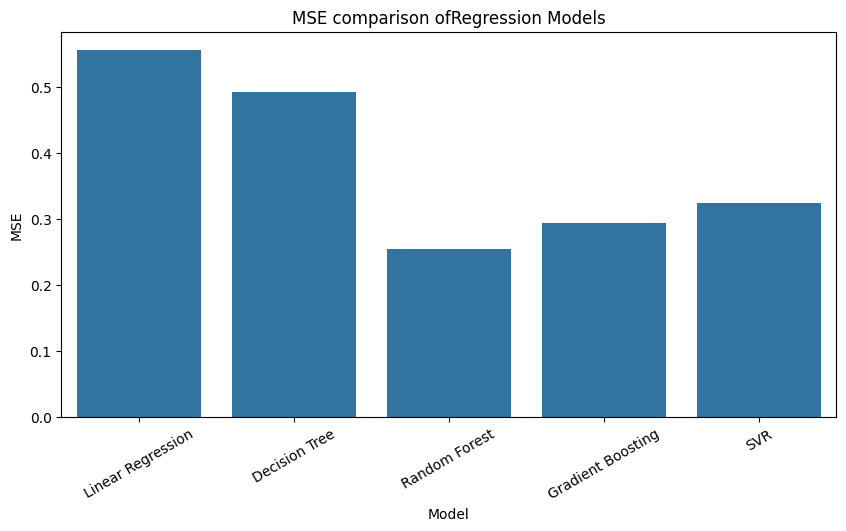

In [146]:
# MSE comparison

plt.figure(figsize=(10,5))
sns.barplot(x='Model',y='MSE',data=results_df)

plt.title('MSE comparison ofRegression Models')
plt.xticks(rotation=30)
plt.show()

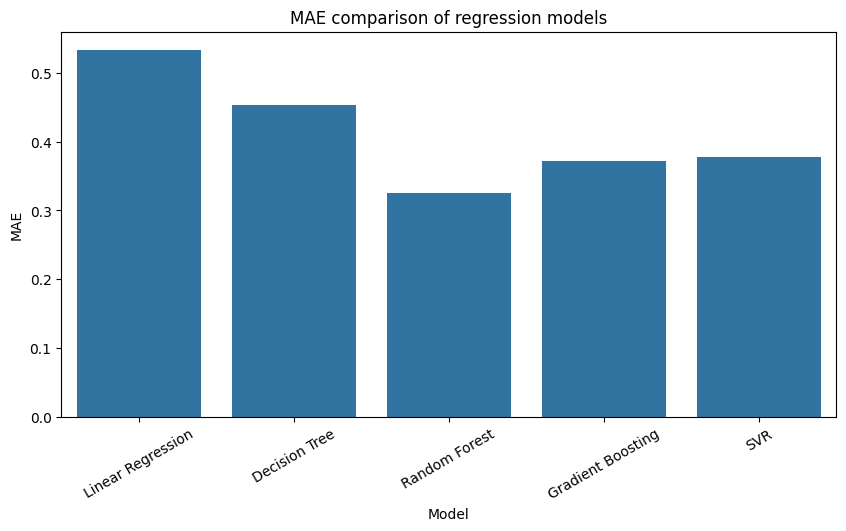

In [147]:
# MAE comparison

plt.figure(figsize=(10,5))
sns.barplot(x='Model',y='MAE',data=results_df)

plt.title('MAE comparison of regression models')
plt.xticks(rotation=30)
plt.show()

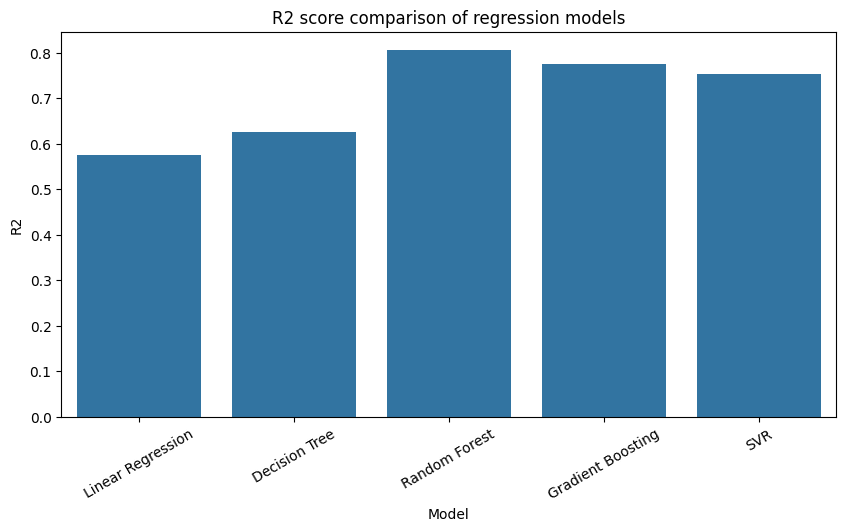

In [148]:
# R2 score comparison

plt.figure(figsize=(10,5))

sns.barplot(x='Model',y='R2',data=results_df)

plt.title('R2 score comparison of regression models')
plt.xticks(rotation=30)
plt.show()

# CONCLUSION

Why is Random Forest the best?
- It has the lowest MSE (0.255260).
- It has the lowest MAE (0.327037).
- It has the highest R² score (0.805206).
- It explains approximately 80.52% of the variation in house prices.

Why is Linear Regression the worst?
- It has the highest MSE (0.555892).
- It has the highest MAE (0.533200).
- It has the lowest R² score (0.575788).

Among the five regression algorithms, Random Forest Regressor performed the best, achieving the lowest MSE and MAE and the highest R² score. It performed better because it combines multiple decision trees to capture complex and nonlinear relationships in the housing data.

Linear Regression performed the worst because it could not effectively capture all the complex relationships between the input features and house prices.